# Ce que les sociétés minières versent vraiment à l'État

**Question :** combien chaque société minière a-t-elle payé à l'État guinéen en 2022 et en 2023 ? Et les chiffres de l'État, des sociétés et du ministère des Mines sont-ils d'accord ?

**La source : l'ITIE.** L'Initiative pour la transparence dans les industries extractives oblige chaque pays membre à publier, chaque année, ce que les sociétés disent avoir payé **et** ce que l'État dit avoir reçu, société par société. Un cabinet indépendant (Moore Insight pour la Guinée) compare les deux : c'est le **rapprochement**.

**Comment on a eu les données :** les rapports ne sont publiés qu'en PDF (434 pages en 2022, 401 en 2023). Le script `src/extraire_itie.py` trouve tout seul la bonne page et reconstruit le tableau à partir de la position des mots (`src/itie.py`). Pour vérifier l'extraction, on recalcule la somme des sociétés : elle est égale à la ligne Total du rapport, au franc près, pour les deux années.

**Données :**
- `data/itie_paiements_par_societe.csv` : le tableau extrait (en francs guinéens), 13 sociétés en 2022, 18 en 2023.
- `data/itie_societes.csv` : le nom court et le produit de chaque société. Les noms changent d'un rapport à l'autre (« SOCIETE MINIERE DE BOKE (SMB)-SA » en 2023, « SOCIETE MINIERE DE BOKE SA » en 2022).
- `data/itie_taux_change.csv` : le cours du dollar donné par chaque rapport (BCRG, fin d'année), pour tout convertir en dollars.

**Quel chiffre on utilise :** sauf mention contraire, le montant **confirmé par l'État après ajustements** : c'est l'argent réellement arrivé dans les caisses publiques.

In [1]:
import sys
sys.path.append("..")

from src.requetes import requete
from src.graphiques import graphique_paiements_societes, graphique_declarations, graphique_paiement_par_tonne

## 1. Qui paie le plus ?

,rang,nom_court,produit,millions_usd,part_pct
0,1,SMB,bauxite,215.2,45.4
1,2,CBG,bauxite,116.1,24.5
2,3,CHALCO,bauxite,24.9,5.2
3,4,CDM CHINE,bauxite,17.7,3.7
4,5,SIMFER,fer,16.4,3.5
5,6,SAG,or,15.8,3.3
6,7,AGB2A,bauxite,12.0,2.5
7,8,SMD,or,10.3,2.2
8,9,GGE,or,10.0,2.1
9,10,COBAD,bauxite,7.0,1.5


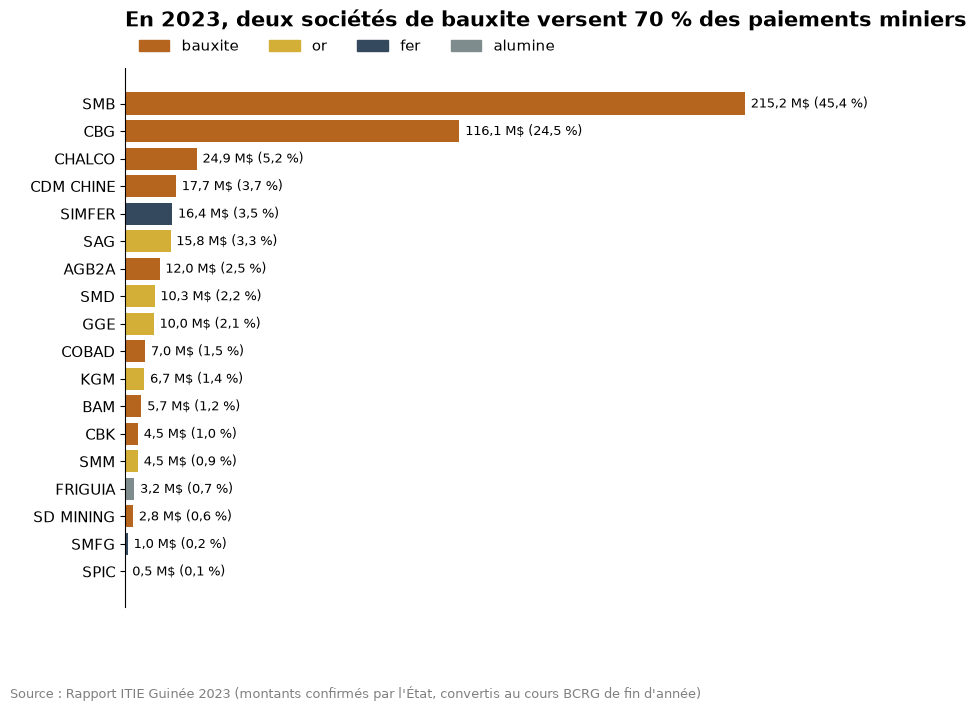

In [2]:
paiements_2023 = requete("07_paiements_par_societe", annee=2023).df()
display(paiements_2023)
graphique_paiements_societes(paiements_2023, 2023)

In [3]:
requete("07_paiements_par_societe", annee=2022).df()

,rang,nom_court,produit,millions_usd,part_pct
0,1,SMB,bauxite,179.8,26.6
1,2,CBG,bauxite,133.6,19.8
2,3,CHALCO,bauxite,87.6,12.9
3,4,SAG,or,65.1,9.6
4,5,GAC,bauxite,60.9,9.0
5,6,SMD,or,43.3,6.4
6,7,CDM CHINE,bauxite,41.2,6.1
7,8,SMM,or,23.6,3.5
8,9,SPIC,bauxite,21.4,3.2
9,10,COBAD,bauxite,8.7,1.3


**Constat :** en 2023, les 18 sociétés du périmètre ont versé **474 millions de dollars** à l'État.
- **SMB** (45 %) et **CBG** (25 %) en versent à elles deux **70 %**. En 2022, elles n'en versaient que 46 % : les paiements sont **de plus en plus concentrés**.
- La bauxite domine, mais pas seulement par son poids : la première société d'or (SAG) n'arrive qu'au 6e rang en 2023, alors qu'elle était 4e en 2022.
- **SIMFER** (Simandou) apparaît pour la première fois en 2023, 5e avec 16 M$, alors qu'elle n'exporte encore rien : ce sont donc des paiements de la phase de construction (probablement des droits et taxes sur le matériel importé ; le tableau ne donne pas le détail).

## 2. Par produit : bauxite, or, fer, alumine

In [4]:
requete("07_paiements_par_produit").df()

,produit,usd_2022,usd_2023,part_2023_pct
0,bauxite,538.2,406.4,85.7
1,or,132.0,47.3,10.0
2,fer,2.9,17.3,3.7
3,alumine,3.4,3.2,0.7


**Constat :**
- **Bauxite : 538 → 406 M$ (-24 %)**, alors que les exportations de bauxite sont passées de 102 à 127 millions de tonnes (+24 %, étape 1). Ce n'est donc pas un problème de volume.
- **Or : 132 → 47 M$ (-64 %)**. Les trois sociétés d'or de 2022 (SAG, SMD, SMM) ont toutes baissé d'au moins 76 %.
- **Fer : 3 → 17 M$**, grâce à l'arrivée de SIMFER. C'est le début de Simandou dans les recettes de l'État.
- La bauxite pèse **86 %** des paiements de 2023. Pour comparer : selon le même rapport (page 10), l'or a rapporté **plus** à l'exportation que la bauxite en 2023 (30 835 milliards de GNF contre 27 288). **L'or rapporte beaucoup moins à l'État que la bauxite, pour une valeur exportée plus grande.**

## 3. Société par société : 2022 contre 2023

In [5]:
requete("07_evolution").df()

,nom_court,usd_2022,usd_2023,variation_pct,remarque
0,SMB,179.8,215.2,20.0,NaN
1,CBG,133.6,116.1,-13.0,NaN
2,CHALCO,87.6,24.9,-72.0,NaN
3,CDM CHINE,41.2,17.7,-57.0,NaN
4,SIMFER,NaN,16.4,NaN,nouvelle en 2023
5,SAG,65.1,15.8,-76.0,NaN
6,AGB2A,NaN,12.0,NaN,nouvelle en 2023
7,SMD,43.3,10.3,-76.0,NaN
8,GGE,NaN,10.0,NaN,nouvelle en 2023
9,COBAD,8.7,7.0,-20.0,NaN


**Constat :**
- Une seule grande société paie plus en 2023 : **SMB (+20 %)**.
- Presque toutes les autres paient moins : CBG -13 %, CDM CHINE -57 %, CHALCO -72 %, SPIC -98 %.
- **GAC disparaît** du tableau en 2023 (61 M$ en 2022) : elle n'a pas atteint le seuil pour faire partie du périmètre, ou n'a pas été retenue.
- **Six sociétés entrent** dans le périmètre en 2023 (SIMFER, AGB2A, GGE, KGM, BAM, SD MINING). Le périmètre change chaque année (seuil : plus de 1 % des revenus miniers), il faut donc comparer **société par société**, pas seulement les totaux.

## 4. Ce que la société déclare contre ce que l'État déclare

,nom_court,selon_societe_musd,selon_etat_musd,ecart_musd,constat
0,SMB,386.7,215.2,171.6,la société déclare plus
1,CHALCO,70.1,24.9,45.2,la société déclare plus
2,SMM,26.6,4.5,22.2,la société déclare plus
3,CDM CHINE,0.0,17.7,-17.7,aucune déclaration de la société
4,SIMFER,0.0,16.4,-16.4,aucune déclaration de la société
5,SAG,0.0,15.8,-15.8,aucune déclaration de la société
6,SMD,22.8,10.3,12.4,la société déclare plus
7,AGB2A,0.0,12.0,-12.0,aucune déclaration de la société
8,GGE,0.0,10.0,-10.0,aucune déclaration de la société
9,COBAD,0.0,7.0,-7.0,aucune déclaration de la société


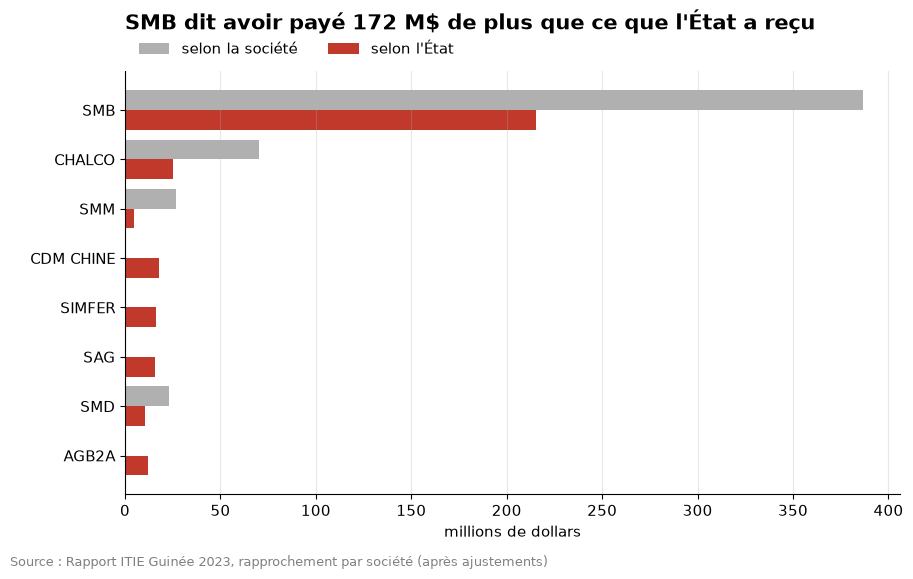

In [6]:
ecarts_2023 = requete("07_ecarts_declarations", annee=2023).df()
display(ecarts_2023)
graphique_declarations(ecarts_2023, 2023)

In [7]:
requete("07_ecarts_declarations", annee=2022).df()

,nom_court,selon_societe_musd,selon_etat_musd,ecart_musd,constat
0,SMB,207.2,179.8,27.3,la société déclare plus
1,CHALCO,69.9,87.6,-17.7,l'État déclare plus
2,SAG,56.0,65.1,-9.1,l'État déclare plus
3,CDM CHINE,50.1,41.2,8.9,la société déclare plus
4,SPIC,16.2,21.4,-5.2,l'État déclare plus
5,GAC,56.0,60.9,-4.9,l'État déclare plus
6,SMD,40.0,43.3,-3.3,l'État déclare plus
7,CBK,7.6,4.9,2.7,la société déclare plus
8,SMM,24.9,23.6,1.3,la société déclare plus
9,CBG,132.9,133.6,-0.7,concordant (moins de 5 %)


**Constat :**
- **2022 :** les déclarations concordent bien. Pour CBG, COBAD, FRIGUIA et SMFG, l'écart est de moins de 5 %. Le plus gros écart (SMB, 27 M$) représente 13 % de ses paiements.
- **2023 :** les écarts explosent. **SMB dit avoir payé 387 M$, l'État dit avoir reçu 215 M$ : 172 M$ d'écart.** CHALCO déclare presque trois fois plus que l'État (70 contre 25 M$).
- **10 sociétés sur 18 n'ont rendu aucune déclaration en 2023** (le rapport le confirme : seules 8 ont envoyé leur formulaire). Pour elles, on n'a que la version de l'État.
- **CBG reste concordante** les deux années. C'est aussi la seule grande société dont l'État est actionnaire (49 %).

Un écart n'est pas forcément une fraude : un paiement peut être enregistré par l'État l'année suivante, ou versé sur un compte que l'État n'a pas déclaré. Mais c'est exactement ce que l'ITIE sert à repérer.

## 5. Contrôle croisé avec le ministère des Mines

In [8]:
requete("07_itie_contre_annuaire").df()

,nom_court,annuaire_mines_musd,itie_selon_etat_musd,itie_selon_societe_musd,constat
0,SMB,185.1,215.2,386.7,cohérent : l'ITIE couvre plus d'impôts
1,CHALCO,44.3,24.9,70.1,incohérent : l'ITIE (tous impôts) est plus bas...
2,CDM CHINE,35.0,17.7,0.0,incohérent : l'ITIE (tous impôts) est plus bas...
3,CBG,18.8,116.1,112.3,cohérent : l'ITIE couvre plus d'impôts
4,SPIC,10.7,0.5,0.0,incohérent : l'ITIE (tous impôts) est plus bas...
5,BAM,7.9,5.7,0.0,incohérent : l'ITIE (tous impôts) est plus bas...
6,COBAD,2.8,7.0,0.0,cohérent : l'ITIE couvre plus d'impôts
7,CBK,0.6,4.5,5.5,cohérent : l'ITIE couvre plus d'impôts


**Pourquoi ce contrôle :** à l'étape 2, on a utilisé l'annuaire 2023 du ministère des Mines, qui donne pour chaque société trois taxes : la taxe minière, les droits de douane et la contribution communautaire. L'ITIE, elle, compte **tous** les paiements (ces trois taxes plus l'impôt sur les sociétés, les dividendes, les cotisations sociales…). Le chiffre ITIE devrait donc toujours être **plus grand**.

**Constat :**
- Pour **SMB, CBG, COBAD et CBK**, c'est bien le cas : les deux sources sont cohérentes.
- Pour **CHALCO, CDM CHINE, SPIC et BAM**, c'est l'inverse : l'État déclare à l'ITIE **moins** que ce que le ministère publie pour trois taxes seulement. Exemple : SPIC, 10,7 M$ selon le ministère, 0,5 M$ selon l'ITIE.
- Pour CHALCO, la déclaration de la société à l'ITIE (70 M$) est, elle, cohérente avec le ministère (44 M$). **Le chiffre qui pose problème est celui de l'État à l'ITIE**, pas celui de la société.

**Conclusion :** pour ces sociétés, les paiements 2023 « confirmés par l'État » sont probablement **sous-estimés**. Les baisses de la partie 3 (CHALCO -72 %, SPIC -98 %) sont donc à prendre avec prudence.

## 6. Combien l'État touche par tonne de bauxite exportée

,nom_court,usd_tonne_2022,usd_tonne_2023
0,CBG,8.23,6.87
1,SMB,5.00,4.41
2,COBAD,3.20,3.38
3,CHALCO,5.95,1.98
4,BAM,NaN,1.87
5,CDM CHINE,4.17,1.87
6,CBK,7.94,1.62
7,SPIC,5.73,0.15
8,GAC,4.20,NaN


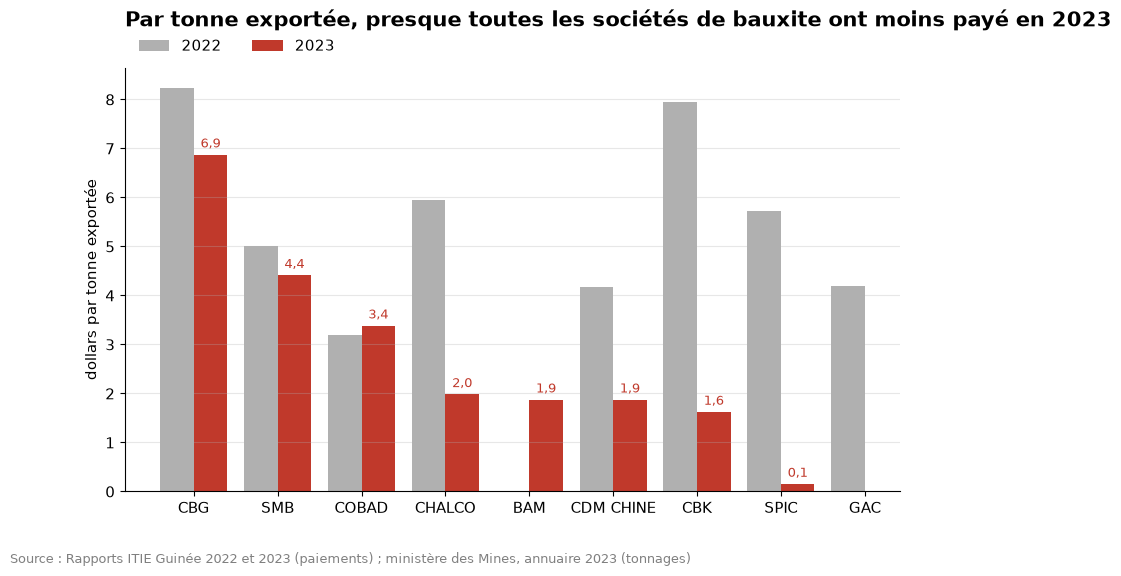

In [9]:
par_tonne = requete("07_paiement_par_tonne").df()
display(par_tonne)
graphique_paiement_par_tonne(par_tonne)

In [10]:
# rappel de l'étape 2 : la taxe minière seule, par tonne exportée (annuaire du ministère)
requete("02_taxe_par_tonne", annee=2023).df()

,entreprise,taxe_miniere_usd,exportation_t,usd_par_tonne
0,BAM,7.672437e+06,3049772,2.515741
1,CBK,6.335690e+05,2782274,0.227716
2,CDM CHINE,3.324749e+07,9469923,3.510851
3,CHALCO,4.237920e+07,12578141,3.369274
4,GAC,3.193138e+07,14147521,2.257030
5,SMB,1.691096e+08,48786555,3.466316
6,SPIC,1.010118e+07,3154257,3.202398


**Constat :**
- **CBG est la société qui paie le plus par tonne** : 8,2 $ en 2022, 6,9 $ en 2023. SMB, qui exporte presque trois fois plus, paie 4,4 $ par tonne.
- En 2023, la plupart des sociétés paient **moins de 2 $ par tonne** selon l'ITIE (CHALCO, CDM CHINE, BAM, CBK), et SPIC 0,15 $.
- Comparé à l'étape 2 : la taxe minière **seule** représente 3,2 à 3,5 $ par tonne pour CHALCO, CDM CHINE, SPIC et SMB. Une société ne peut pas payer moins au total que sa seule taxe minière : cela confirme que les chiffres de l'État à l'ITIE sont incomplets pour plusieurs sociétés en 2023 (partie 5).
- **Pour comparer :** à l'étape 3, une tonne de bauxite guinéenne valait environ **64 $** à l'arrivée en Chine en 2022. Avec 4 à 8 $ par tonne, l'État guinéen touche **environ 10 % ou moins** de cette valeur.

## Conclusions

1. **Deux sociétés de bauxite (SMB et CBG) versent 70 % des paiements miniers** en 2023. Les recettes de l'État dépendent de très peu d'acteurs.
2. **Les paiements baissent de 2022 à 2023** (677 → 474 M$), alors que les exportations de bauxite augmentent. L'or rapporte de moins en moins.
3. **Simandou commence à payer** (16 M$ pour SIMFER en 2023), avant même la première exportation.
4. **La qualité des données se dégrade en 2023** : 10 sociétés sur 18 sans déclaration, 172 M$ d'écart pour SMB, et des chiffres de l'État plus bas que ceux du ministère des Mines pour 4 sociétés.
5. **CBG est la référence** : déclarations concordantes les deux années et le plus haut paiement par tonne.

## Limites

- Le périmètre ITIE change chaque année : 13 sociétés en 2022, 18 en 2023. Les totaux ne sont pas directement comparables.
- Le rapport ITIE 2023 ne couvre que **65 %** des revenus miniers de l'État (le reste est déclaré par l'État sans rapprochement, page 12 du rapport).
- Les montants sont convertis en dollars au cours de fin d'année : une partie des variations vient du taux de change.
- Les fiches de rapprochement détaillées (une par société, en annexe) sont des **images scannées** : notre extraction ne peut pas les lire. C'est l'objet de la suite de l'étape 7.